# Title

**Exercise 2 - Simple k-NN Classification and Logistic Regression**

# Description
The aim of this exercise is to fit, interpret, predict, score, and plot simple $k$-NN classification and logistic regression models using the `sklearn` package.

In the end, you should get a plot that looks like this (way too busy for publication, but OK here for teaching purposes):

<img src="../img/image2.png" style="width: 500px;">

# Dataset Description:

The dataset used here is called the Heart dataset. This dataset has several predictors such as `Age`, `Sex`, and `MaxHR`, etc.  For now, we will just use `Age` to predict whether or not someone has atherosclerotic heart disease (AHD).

# Instructions:
1. Read the `Heart.csv` file into a pandas data frame.
2. Split the dataset into train and validation sets, with 80% of the data for training
3. Assign the predictor and response variables. Remember the aim is to predict whether a patient has `AHD`
4. Fit a $k$-NN model (manually tuned) to the dataset and look at some predictions.
5. Fit a logistic regression model to the dataset and interpret the coefficients. 
6. Do some work mathematically based on the estimated model.
7. Compute and print the train and validation accuracies for both
8. Plot the predictions on the scatterplot.

# Hints:

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html" target="_blank">sklearn.KNeighborsClassifier()</a> : Generates a $k$-NN classifier

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html" target="_blank">sklearn.LogisticRegression()</a> : Generates a Logistic Regression classifier

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.fit" target="_blank">sklearn.fit()</a> : Fits the model to the given data

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict" target="_blank">sklearn.predict()</a> : Predict using the estimated model (Logistic or knn classifiers) to perform pure classification predictions

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict_proba" target="_blank">sklearn.predict_proba()</a> : Predict using the estimated model (Logistic or knn classifiers) to perform probability predictions of all the classes in the response (they should add up to 1 for each observation)

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html" target="_blank">sklearn.LogisticRegression.coef_ and .intercept_</a> : Pull off the estimated $\beta$ coefficients in a Logistic Regression model

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.score" target="_blank">sklearn.score()</a> : Accuracy classification score.

**Note: This exercise is auto-graded and you can try multiple attempts.**

In [1]:
# import libraries

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier 

### Read-in the dataset

In [2]:
# Read the "Heart.csv" dataset and take a quick look
heart = pd.read_csv('Heart.csv')

# Force the response into a binary indicator:
heart['AHD'] = 1*(heart['AHD'] == "Yes")

print(heart.shape)

(303, 15)


In [3]:
# split into train and validation
heart_train, heart_val = train_test_split(heart, train_size = 0.75, random_state = 109)

print(heart_train.shape, heart_val.shape)

(227, 15) (76, 15)


### $k$-NN model fitting

Define and fit a $k$-NN classification model with $k=20$ to predict `AHD` from `Age`.

In [4]:
# select variables for model estimation: be careful of format 
# (aka, single or double square brackets)
x_train = heart_train[["Age"]]
y_train = heart_train["AHD"]

# define the model
knn20 = KNeighborsClassifier(20)

# fit to the data
knn20.fit(x_train , y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",20
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### $k$-NN prediction

Perform some simple predictions: both the pure classifications and the probability estimates.

In [5]:
### edTest(test_knn) ###

# there are two types of predictions in classification models in sklearn
# model.predict for pure classifications, and model.predict_proba for probabilities

# create the predictions based on the train data
yhat20_class = knn20.predict(x_train)
yhat20_prob = knn20.predict_proba(x_train)

# print out the first 10 predictions for the actual data
print(yhat20_class[1:10])
print(yhat20_prob[1:10])

[0 1 1 1 0 1 1 0 1]
[[0.8  0.2 ]
 [0.4  0.6 ]
 [0.25 0.75]
 [0.3  0.7 ]
 [0.7  0.3 ]
 [0.45 0.55]
 [0.3  0.7 ]
 [0.7  0.3 ]
 [0.35 0.65]]


What do you notice about the probability estimates?  Which 'column' is which?  How could you manually create `yhat20_class` from `yhat20_prob`? 

The first column represents the probability for the sample to 0 (not have AHD) and the second, to to be 1 (have AHD). Seelct the class with the higher probability.

### Simple logisitc regression model fitting

Define and fit a $k$-NN classification model with $k=20$ to predict `AHD` from `Age`.

In [6]:
### edTest(test_logit) ###
# Create a logistic regression model, with 'none' as the penalty

logit1 = LogisticRegression(penalty=None, max_iter = 1000)

#Fit the model using the training set

logit1.fit(x_train,y_train)

# Get the coefficient estimates

print("Logistic Regression Estimated Betas (B0,B1):",logit1.intercept_,logit1.coef_)


Logistic Regression Estimated Betas (B0,B1): [-3.32616703] [[0.05933142]]


c:\Users\biaon\Desktop\DataScience\Section5\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### Interpret the Coefficient Estimates

Write down the logistic regression model below (edit the provided latex formula).  Use this formula to answer: 

What is the estimated odds that a 60 year old will have AHD in the ICU?  What is the probability?

$$ \ln\left(  \frac{P(Y=1)}{1-P(Y=1)} \right) = \hat{\beta}_0 + \hat{\beta}_1 X$$

$$ \ln\left(  \frac{P(Y=1)}{1-P(Y=1)} \right) = -3.32616703 + 0.05933142 X$$

0,293 to have AHD

In [7]:
# Make the predictions on the training & validation set
# Be careful as to how you define the new observation.  Hint: double brackets is one way to do it

logit1.predict(x_train)

array([0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 1, 1, 1, 1])

### Accuracy computation

### $k$-NN and logistic accuracy

In [8]:
### edTest(test_accuracy) ###

# Define the equivalent validation variables from `heart_val`

x_val = heart_val[["Age"]]
y_val = heart_val["AHD"]

# Compute the training & validation accuracy using the estimator.score() function

knn20_train_accuracy = knn20.score(x_train, y_train)
knn20_val_accuracy = knn20.score(x_val, y_val)

logit_train_accuracy = logit1.score(x_train, y_train)
logit_val_accuracy = logit1.score(x_val, y_val)

# Print the accuracies below

print("k-NN Train & Validation Accuracy:", knn20_train_accuracy, knn20_val_accuracy)
print("Logisitic Train & Validation Accuracy:", logit_train_accuracy, logit_val_accuracy)




k-NN Train & Validation Accuracy: 0.6299559471365639 0.5526315789473685
Logisitic Train & Validation Accuracy: 0.6387665198237885 0.6052631578947368


### Plot the predictions

Use a 'dummy' x variable for plotting for the two different models.  Here we plot the train and validation data separately, and the 4 different types of predictions (2 for each model: pure classification and probability estimation)

c:\Users\biaon\Desktop\DataScience\Section5\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
c:\Users\biaon\Desktop\DataScience\Section5\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
c:\Users\biaon\Desktop\DataScience\Section5\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\biaon\Desktop\DataScience\Section5\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


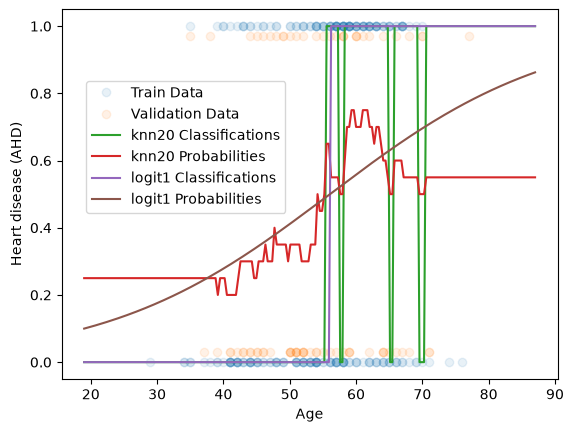

In [9]:

# set-up the dummy x for plotting: we extend it a little bit beyond the range of observed values 
x = np.linspace(np.min(heart[['Age']])-10, np.max(heart[['Age']])+10,200)
x = x.reshape(-1, 1)


# be careful in pulling off only the correct column of the probability calculations: use `[:,1]`
yhat_class_knn20 = knn20.predict(x)
yhat_prob_knn20 = knn20.predict_proba(x)[:,1]

yhat_class_logit = logit1.predict(x)
yhat_prob_logit = logit1.predict_proba(x)[:,1]

# plot the observed data.  Note: we offset the validation points to make them more clearly differentiated from train
plt.plot(x_train, y_train, 'o' ,alpha=0.1, label='Train Data')
plt.plot(x_val, 0.94*y_val+0.03, 'o' ,alpha=0.1, label='Validation Data')

# plot the predictions
plt.plot(x, yhat_class_knn20, label='knn20 Classifications')
plt.plot(x, yhat_prob_knn20, label='knn20 Probabilities')
plt.plot(x, yhat_class_logit, label='logit1 Classifications')
plt.plot(x, yhat_prob_logit, label='logit1 Probabilities')

# put the lower-left part of the legend 5% to the right along the x-axis, and 45% up along the y-axis
plt.legend(loc=(0.05,0.45))

# Don't forget your axis labels!
plt.xlabel("Age")
plt.ylabel("Heart disease (AHD)")

plt.show()


### Post exercise questions

1. Describe the estimated associations between AHD and Age based on these two models.

A person will have AHD if they have 55 years or more

2. Which model apears to be more overfit to the training data?  How do you know?  How can this be resolved?

KNN for it being more variant across the datapoits, jumping between yes and no. Increasing the neighbours.

3. How could you engineer features for the logistic regression model so that the association between AHD and Age resembles the general trend in the knn20 model more similarly?

*Your answer here*

In [10]:
"Add polinomial features to the model, making it able to do more ups and downs."

'Add polinomial features to the model, making it able to do more ups and downs.'

4. Refit the models above to predict `AHD` from 3 predictors (please also play around with $k$):
```{python}
['MaxHR','Age','Sex']
```
Investigate the associations in each of the two models and evaluate the predictive accuracy of each of these models

In [11]:
# Your answer here